In [1]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

In [60]:
base = "/Users/PITLab/Downloads/"
filenames = [
    f"{base}prep_Jul29_3x3_overnight__NEv50000_BV115000mV_MCP4500.root",
    f"{base}prep_Jul29_3x3_overnight__NEv50000_BV117000mV_MCP4500.root",
    f"{base}prep_Jul29_3x3_overnight__NEv50000_BV119000mV_MCP4500.root",
]

legend_labels = []

for f in filenames:
    print(f)
    bias_voltage = f.split("_BV")[1].split("000mV_")[0] + "V"
    wafer = f.split(f"{base}prep_")[1].split("_")[0]
    tag = f.split(f"{base}prep_Jul29_")[1].split("_")[0]
    legend_labels.append(wafer+" "+bias_voltage+" "+tag)

print(legend_labels)

/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV115000mV_MCP4500.root
/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV117000mV_MCP4500.root
/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV119000mV_MCP4500.root
['Jul29 115V 3x3', 'Jul29 117V 3x3', 'Jul29 119V 3x3']


In [64]:
channels = []
time = []
baseline_RMS = []
amp = []
timestamps_10 = []
timestamps_50 = []
timestamps_80 = []

for f, file in enumerate(filenames):
    print(file)
    arrays = uproot.open(file)["pulse"].arrays()
    channels.append(arrays["channel"])
    time.append(arrays["time"])
    baseline_RMS.append(arrays["baseline_RMS"])
    amp.append(arrays["amp"])
    timestamps_10.append(arrays["LP2_10"])
    timestamps_50.append(arrays["LP2_50"])
    timestamps_80.append(arrays["LP2_90"])

/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV115000mV_MCP4500.root
/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV117000mV_MCP4500.root
/Users/PITLab/Downloads/prep_Jul29_3x3_overnight__NEv50000_BV119000mV_MCP4500.root


[7.53, 6.62, 5.34, 6.4, 5.56, 7.21, ..., 15.4, 7.06, 8.13, 9.2, 7.31, 7.47]
[28.9, 21.5, 23.1, 25.3, 21.1, 31.3, 25, ..., 35.4, 36.7, 20.5, 27.4, 22, 39.2]
[6.04, 7.18, 6.03, 5.6, 7.19, 6.96, 7.18, ..., 6.48, 6, 6.95, 31.1, 7.11, 7.08]
[25, 21.4, 24.5, 23.3, 28.7, 33.6, 24.4, ..., 25, 23.4, 40.1, 25.9, 49, 31.2]
[8, 5, 7.55, 6.36, 8.04, 6.93, 5.95, ..., 8, 7.21, 10.1, 7.46, 5.43, 7.1, 6.53]
[20.9, 21.3, 31.1, 25.3, 31.5, 42.6, ..., 49.7, 56.2, 53.5, 21.3, 20.4, 22.8]


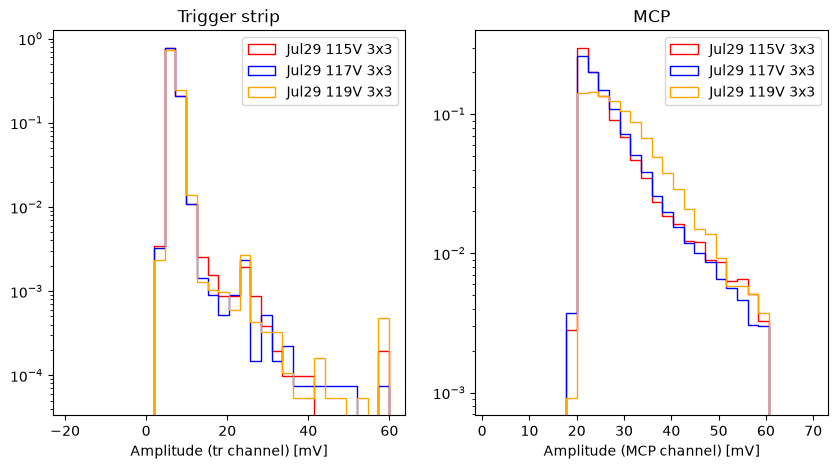

In [73]:
rows = 1
cols = 2 # len(filenames)
size = 5
nbins = 30
# for r in range(20):

colors = ["r", "b", "orange"]

fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

range1 = (
    np.min(
        (np.min(amp[0][:,0]), np.min(amp[1][:,0]), np.min(amp[2][:,0]))
    ), 
    np.max(
        (np.max(amp[0][:,0]), np.max(amp[1][:,0]), np.min(amp[2][:,0]))
    )
)

range2 = (
    np.min(
        (np.min(amp[0][:,1]), np.min(amp[1][:,1]), np.min(amp[2][:,1]))
    ), 
    np.max(
        (np.max(amp[0][:,1]), np.max(amp[1][:,1]), np.min(amp[2][:,1]))
    )
)

for f, file in enumerate(filenames):
    cuts = (amp[f][:,1]<600)&(amp[f][:,1]>20)&(amp[f][:,0]>0)&(amp[f][:,0]<120)&(baseline_RMS[f][:,0]<3)
    cuts = (amp[f][:,1]<60)&(amp[f][:,1]>20)&(amp[f][:,0]>0)&(amp[f][:,0]<120)&(baseline_RMS[f][:,0]<3)

    amp1 = amp[f][cuts][:,0]
    amp2 = amp[f][cuts][:,1]
    
    N1 = len(amp1)
    N2 = len(amp2)
    
    ax[0].hist(amp1, bins = nbins, color = colors[f], range = range1, label = legend_labels[f], histtype = "step", weights = np.ones(N1)*1.0/N1)
    ax[0].set_title("Trigger strip")
    ax[0].set_xlabel("Amplitude (tr channel) [mV]")
    ax[0].set_yscale("log")

    ax[1].hist(amp2, bins = nbins, color = colors[f], range = range2, label = legend_labels[f], histtype = "step", weights = np.ones(N2)*1.0/N2)
    ax[1].set_title("MCP")
    ax[1].set_xlabel("Amplitude (MCP channel) [mV]")
    ax[1].set_yscale("log")

    print(amp1)
    print(amp2)

ax[0].legend()
ax[1].legend()
plt.show()